[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JPEDROPS092/machine-learning-algorithms/blob/main/notebooks/02-sentimentos-imdb-naive-bayes.ipynb)

# Sentimento em criticas do IMDb com Naive Bayes

O corpus e o Large Movie Review Dataset de Maas e colegas, publicado no ACL 2011 e conhecido como aclImdb de Stanford. Sao 25 mil criticas de treino e 25 mil de teste, meio a meio entre positivas e negativas, em ingles.

O caderno baixa o arquivo completo. Para a aula, usa um subconjunto reprodutivel: 1.000 criticas de cada classe no treino (semente 0) e 400 de cada classe no teste (semente 1). O numero completo de arquivos e impresso ao lado da amostra, para ficar claro o que ficou de fora. Se o site de Stanford nao responder, o mesmo corpus e lido do zip historico usado pelo Keras (`s3.amazonaws.com/text-datasets/aclImdb.zip`).


In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q numpy pandas scikit-learn matplotlib seaborn requests
    import os
    if not os.path.isdir("/content/ml-algoritmos/src/mlalgos"):
        !git clone --depth 1 https://github.com/JPEDROPS092/machine-learning-algorithms.git /content/ml-algoritmos
    if "/content/ml-algoritmos/src" not in sys.path:
        sys.path.insert(0, "/content/ml-algoritmos/src")
    PASTA_DADOS = Path("/content/data")
else:
    aqui = Path.cwd().resolve()
    raiz = aqui if (aqui / "src" / "mlalgos").exists() else aqui.parent
    if not (raiz / "src" / "mlalgos").exists():
        raise RuntimeError(
            "Nao encontrei src/mlalgos. Abra o notebook na pasta notebooks ou na raiz do repositorio."
        )
    if str(raiz / "src") not in sys.path:
        sys.path.insert(0, str(raiz / "src"))
    PASTA_DADOS = raiz / "data"

PASTA_DADOS.mkdir(parents=True, exist_ok=True)

%matplotlib inline
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


def baixar(url, destino):
    """Baixa um arquivo so se ele ainda nao estiver na pasta data, que nao entra no git."""
    destino = Path(destino)
    if destino.exists() and destino.stat().st_size > 0:
        return destino
    import requests

    resposta = requests.get(url, timeout=180, headers={"User-Agent": "ml-algoritmos-aula/1.0"})
    resposta.raise_for_status()
    destino.write_bytes(resposta.content)
    return destino


def padronizar(treino, teste):
    """Z-score com media e desvio do treino. O teste usa os mesmos numeros, sem vazar."""
    treino = np.asarray(treino, dtype=float)
    teste = np.asarray(teste, dtype=float)
    media = treino.mean(axis=0)
    desvio = treino.std(axis=0)
    desvio = np.where(desvio == 0, 1.0, desvio)
    return (treino - media) / desvio, (teste - media) / desvio, media, desvio


## 1) Intuição

Uma critica de filme e um voto alongado. "Obra-prima" e "perda de tempo" puxam para lados opostos, e o resto da frase enche o meio. Quem indica filme para um amigo faz essa conta sem escrever: acumula adjetivos e decide.

O Naive Bayes faz a versao explicita. Cada palavra tem uma taxa dentro das criticas positivas e outra dentro das negativas. A critica nova e pontuada pela soma dos logs. A armadilha classica e a negacao: "nao e bom" tem a palavra "bom", que sozinha aponta para o lado positivo. A independencia condicional nao enxerga esse "nao".


## 2) Fundamentação matemática

O teorema de Bayes inverte a pergunta. Em vez de perguntar so quao tipico e o texto dentro de uma classe, calculamos a chance da classe depois de ler o texto:

$$
P(y \mid x) = \frac{P(x \mid y)\, P(y)}{P(x)}
$$

- $P(y \mid x)$ e a probabilidade da classe $y$ depois de observar $x$. E a saida do classificador.
- $P(x \mid y)$ e a verossimilhanca: a chance de ver esse texto se a classe for $y$.
- $P(y)$ e o prior, a frequencia da classe antes de olhar o texto.
- $P(x)$ e a evidencia. Ela nao depende de $y$, entao nao muda qual classe ganha. Na hora de decidir, comparamos $P(x \mid y)\,P(y)$.

A hipotese de independencia condicional, a parte ingênua do nome, diz que, dada a classe, uma palavra nao informa a outra:

$$
P(x \mid y) = \prod_{j=1}^{d} P(x_j \mid y)
$$

- $x_j$ e a contagem da palavra $j$.
- $d$ e o tamanho do vocabulario.
- O produto e falso em frases reais ("nao" muda "bom"), mas o erro muitas vezes se reparte e o sinal de cada palavra ainda aponta a classe certa.

No modelo multinomial a probabilidade de uma palavra e a fatia dela nas contagens da classe. A suavizacao de Laplace soma $\alpha$ para uma palavra nunca vista nao zerar o produto inteiro:

$$
\hat{P}(w \mid y) = \frac{n_{y,w} + \alpha}{n_y + \alpha \, |V|}
$$

- $n_{y,w}$ e quantas vezes a palavra $w$ apareceu na classe $y$.
- $n_y$ e a soma de todas as contagens da classe.
- $|V|$ e o numero de palavras do vocabulario.
- $\alpha$ e a forca da suavizacao. Com $\alpha = 1$ ha uma ocorrencia ficticia de cada palavra em cada classe.

Mil probabilidades pequenas, multiplicadas, estouram para zero no computador. O logaritmo transforma o produto em soma:

$$
\log P(y \mid x) \propto \log P(y) + \sum_{j=1}^{d} x_j \, \log \hat{P}(w_j \mid y)
$$

- $\log P(y)$ e o prior em escala de log.
- $x_j \log \hat{P}(w_j \mid y)$ pesa a palavra pela contagem dela neste texto. Palavra ausente entra com zero.
- A classe escolhida e a de maior soma. Para converter as somas em probabilidades que somam 1, subtraimos o log-sum-exp de todas as classes.

Nesta colecao as duas classes foram balanceadas de proposito, entao $\log P(y)$ quase nao decide. Quem decide e a soma das palavras. Isso e diferente do spam, em que o prior ja empurra para ham.


## 3) Visualização

O grafico de baixo usa o subconjunto da aula, nao o corpus inteiro. O comprimento esta em caracteres, antes de cortar o vocabulario.


nao deu para usar https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz SSLError


fonte usada: https://s3.amazonaws.com/text-datasets/aclImdb.zip
arquivos no treino completo 25000
arquivos no teste completo 25000


amostra de treino 2000 amostra de teste 800


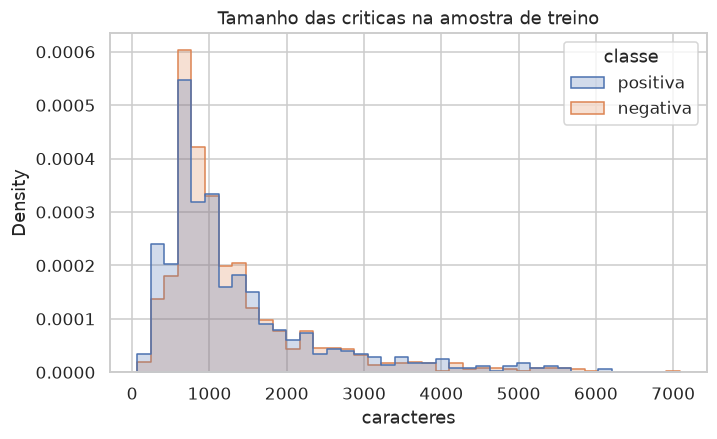

In [2]:
import tarfile
import zipfile

raiz_imdb = PASTA_DADOS / "aclImdb"
if not (raiz_imdb / "train" / "pos").exists():
    fonte_usada = None
    candidatos = [
        ("https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz", "gz"),
        ("https://s3.amazonaws.com/text-datasets/aclImdb.zip", "zip"),
    ]
    for url, tipo in candidatos:
        try:
            nome = PASTA_DADOS / ("aclImdb_v1.tar.gz" if tipo == "gz" else "aclImdb.zip")
            baixar(url, nome)
            if tipo == "zip":
                with zipfile.ZipFile(nome) as pacote:
                    pacote.extractall(PASTA_DADOS)
            else:
                with tarfile.open(nome, "r:gz") as pacote:
                    pacote.extractall(PASTA_DADOS)
            fonte_usada = url
            break
        except Exception as erro:
            print("nao deu para usar", url, type(erro).__name__)
    if fonte_usada is None or not (raiz_imdb / "train" / "pos").exists():
        raise RuntimeError("Nao consegui obter o corpus aclImdb.")
    print("fonte usada:", fonte_usada)
else:
    print("corpus ja estava em", raiz_imdb)

def contar_arquivos(split):
    return len(list((raiz_imdb / split / "pos").glob("*.txt"))) + len(list((raiz_imdb / split / "neg").glob("*.txt")))

print("arquivos no treino completo", contar_arquivos("train"))
print("arquivos no teste completo", contar_arquivos("test"))

def amostra(split, por_classe, semente):
    rng = np.random.default_rng(semente)
    textos, ys = [], []
    for classe, pasta in [(1, "pos"), (0, "neg")]:
        arquivos = sorted((raiz_imdb / split / pasta).glob("*.txt"))
        escolhidos = rng.choice(len(arquivos), size=por_classe, replace=False)
        for i in escolhidos:
            texto = arquivos[int(i)].read_text(encoding="utf-8", errors="replace")
            textos.append(texto.replace("<br />", " "))
            ys.append(classe)
    return textos, np.array(ys)

X_treino_txt, y_treino = amostra("train", 1000, 0)
X_teste_txt, y_teste = amostra("test", 400, 1)
df = pd.DataFrame({
    "tamanho": [len(t) for t in X_treino_txt],
    "classe": np.where(y_treino == 1, "positiva", "negativa"),
})
print("amostra de treino", len(y_treino), "amostra de teste", len(y_teste))
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=df, x="tamanho", hue="classe", bins=40, element="step", stat="density", ax=ax)
ax.set_title("Tamanho das criticas na amostra de treino")
ax.set_xlabel("caracteres")
plt.show()


## 4) Implementação do zero

O vocabulario fica nas 4.000 palavras mais frequentes do treino da amostra. Sem esse corte, nome de ator que aparece uma vez vira coluna. O corte e uma escolha da aula, nao do corpus original.


matriz (2000, 4000)


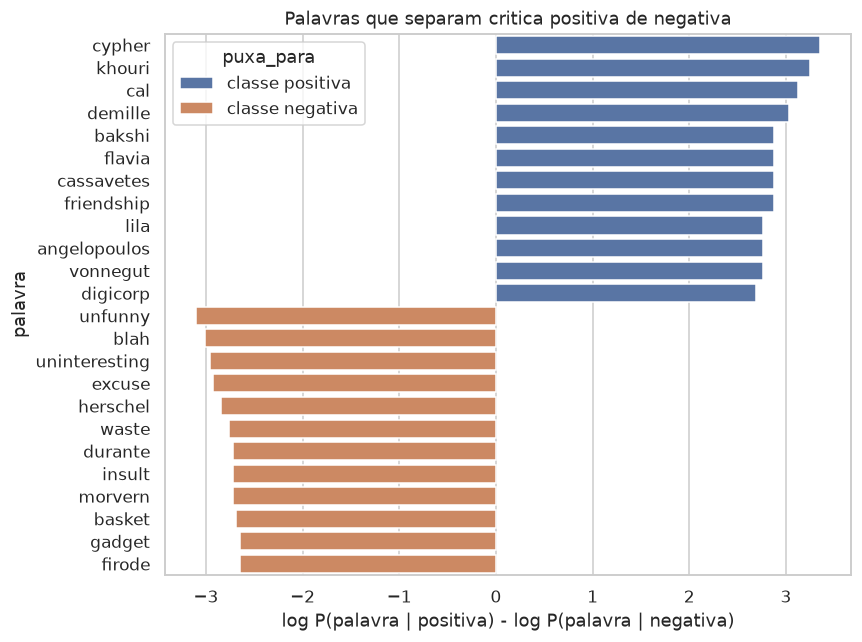

In [3]:
from mlalgos import MultinomialNB, TfidfVectorizer

# Contagem, nao TF-IDF: o multinomial foi feito para contagens.
from mlalgos import BagOfWords

vetor = BagOfWords(max_features=4000)
X_treino = vetor.fit_transform(X_treino_txt)
X_teste = vetor.transform(X_teste_txt)
nb = MultinomialNB(alpha=1.0).fit(X_treino, y_treino)
print("matriz", X_treino.shape)
indice = {classe: i for i, classe in enumerate(nb.classes_)}
delta = nb.feature_log_prob_[indice[1]] - nb.feature_log_prob_[indice[0]]
vocabulario = np.empty(len(vetor.vocabulary_), dtype=object)
for token, coluna in vetor.vocabulary_.items():
    vocabulario[coluna] = token
ordem = np.argsort(delta)
k = 12
tabela = pd.DataFrame({
    "palavra": np.concatenate([vocabulario[ordem[-k:][::-1]], vocabulario[ordem[:k]]]),
    "diferenca_de_log": np.concatenate([delta[ordem[-k:][::-1]], delta[ordem[:k]]]),
    "puxa_para": ["classe positiva"] * k + ["classe negativa"] * k,
})
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=tabela, y="palavra", x="diferenca_de_log", hue="puxa_para", dodge=False, ax=ax)
ax.set_title('Palavras que separam critica positiva de negativa')
ax.set_xlabel("log P(palavra | positiva) - log P(palavra | negativa)")
plt.tight_layout()
plt.show()


## 5) Implementação com scikit-learn

A comparacao estrita usa a mesma matriz. O pipeline mostra o caminho de biblioteca, com o `CountVectorizer` dele e o mesmo teto de 4.000 palavras. A selecao das 4.000 pode nao ser identica a nossa, entao as metricas do pipeline podem diferir um pouco; as probabilidades da mesma matriz nao.


In [4]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB as SkMultinomialNB
from sklearn.pipeline import Pipeline

sk = SkMultinomialNB(alpha=1.0).fit(X_treino, y_treino)
diferenca = np.max(np.abs(nb.predict_proba(X_teste) - sk.predict_proba(X_teste)))
acordo = float(np.mean(nb.predict(X_teste) == sk.predict(X_teste)))
print(f"maior diferenca absoluta entre probabilidades: {diferenca:.3e}")
print(f"concordancia das classes previstas: {acordo:.3f}")

cano = Pipeline([
    ("contagem", CountVectorizer(max_features=4000)),
    ("nb", SkMultinomialNB(alpha=1.0)),
])
cano.fit(X_treino_txt, y_treino)
print("acuracia do pipeline na amostra de teste", float(cano.score(X_teste_txt, y_teste)))


maior diferenca absoluta entre probabilidades: 0.000e+00
concordancia das classes previstas: 1.000


acuracia do pipeline na amostra de teste 0.80625


## 6) Avaliação

Os numeros valem para o subconjunto descrito no inicio, nao para as 50 mil criticas. Classe positiva = critica positiva.


acuracia 0.807 | baseline da classe majoritaria 0.500
precisao 0.838 | revocacao 0.762 | f1 0.798 | roc_auc 0.885
RESUMO_METRICAS {"modelo": "multinomial_nb_imdb_amostra", "acuracia": 0.8075, "precisao": 0.8379120879120879, "revocacao": 0.7625, "f1": 0.7984293193717278, "roc_auc": 0.8853375, "baseline_majoritaria": 0.5}


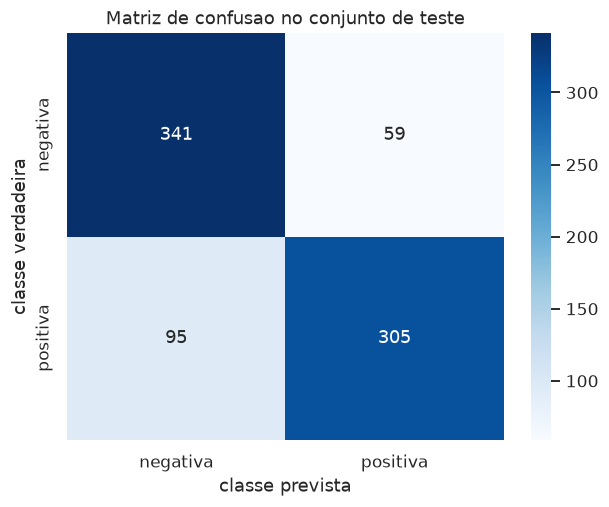

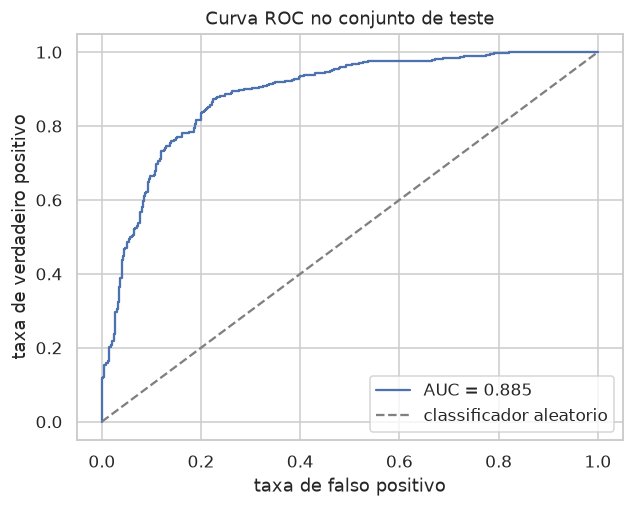

In [5]:
from mlalgos.metrics import confusion_matrix, curva_roc, f1_score, precision_score, recall_score, roc_auc_score

y_previsto = nb.predict(X_teste)
y_escore = nb.predict_proba(X_teste)[:, 1]
acuracia = float(np.mean(y_previsto == y_teste))
precisao = precision_score(y_teste, y_previsto, pos_label=1)
revocacao = recall_score(y_teste, y_previsto, pos_label=1)
f1 = f1_score(y_teste, y_previsto, pos_label=1)
auc = roc_auc_score(y_teste, y_escore, pos_label=1)
baseline = float(max(np.mean(y_teste == 1), np.mean(y_teste == 0)))
print(f"acuracia {acuracia:.3f} | baseline da classe majoritaria {baseline:.3f}")
print(f"precisao {precisao:.3f} | revocacao {revocacao:.3f} | f1 {f1:.3f} | roc_auc {auc:.3f}")
print("RESUMO_METRICAS " + json.dumps({
    "modelo": 'multinomial_nb_imdb_amostra',
    "acuracia": acuracia,
    "precisao": precisao,
    "revocacao": revocacao,
    "f1": f1,
    "roc_auc": auc,
    "baseline_majoritaria": baseline,
}))

cm = confusion_matrix(y_teste, y_previsto, labels=[0, 1])
fig, ax = plt.subplots()
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=['negativa', 'positiva'], yticklabels=['negativa', 'positiva'], ax=ax,
)
ax.set_xlabel("classe prevista")
ax.set_ylabel("classe verdadeira")
ax.set_title("Matriz de confusao no conjunto de teste")
plt.show()

fpr, tpr, _ = curva_roc(y_teste, y_escore, pos_label=1)
fig, ax = plt.subplots()
ax.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="classificador aleatorio")
ax.set_xlabel("taxa de falso positivo")
ax.set_ylabel("taxa de verdadeiro positivo")
ax.set_title("Curva ROC no conjunto de teste")
ax.legend()
plt.show()


## 7) Desafios

1. Ache na amostra de teste uma critica em que aparecem "not" e "good" e o modelo erra. A independencia condicional explica o erro?
2. Troque `max_features` para 500 e para o vocabulario inteiro. O F1 sobe junto com o vocabulario, ou estaciona?
3. O TF-IDF nao e o modelo natural do multinomial, mas da para alimentar o `MultinomialNB` com ele. Compare o F1 com o das contagens e diga o que mudou nas palavras do grafico.
